**Q4. Run Apriori algorithm to find frequent itemsets and association rules**

First use the command **pip install efficient_apriori** on windows power shell

In [4]:
pip install efficient_apriori

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.1.1 -> 24.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import numpy as np
import pandas as pd
from efficient_apriori import apriori

In [6]:
df=pd.read_csv("groceriesDataset.csv")

In [7]:
df.shape

(9835, 33)

In [8]:
display(df)

,Item(s),Item 1,Item 2,Item 3,Item 4,Item 5,Item 6,Item 7,Item 8,Item 9,...,Item 23,Item 24,Item 25,Item 26,Item 27,Item 28,Item 29,Item 30,Item 31,Item 32
0,4,citrus fruit,semi-finished bread,margarine,ready soups,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,3,tropical fruit,yogurt,coffee,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,whole milk,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,pip fruit,yogurt,cream cheese,meat spreads,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,other vegetables,whole milk,condensed milk,long life bakery product,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9830,17,sausage,chicken,beef,hamburger meat,citrus fruit,grapes,root vegetables,whole milk,butter,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9831,1,cooking chocolate,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9832,10,chicken,citrus fruit,other vegetables,butter,yogurt,frozen dessert,domestic eggs,rolls/buns,rum,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9833,4,semi-finished bread,bottled water,soda,bottled beer,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
df["Item(s)"].value_counts()

#The line of code df["Item(s)"].value_counts() is used to count the occurrences of each unique value in the "Item(s)" column of the DataFrame df.
#Let's break it down:
#df["Item(s)"]: This selects the "Item(s)" column from the DataFrame df.
#.value_counts(): This method counts the number of occurrences of each unique value in the selected column.
#The result will be a Series where:
#The index contains the unique values (items) found in the "Item(s)" column.
#The values are the counts of how many times each unique item appears.**

Item(s)
1     2159
2     1643
3     1299
4     1005
5      855
6      645
7      545
8      438
9      350
10     246
11     182
12     117
13      78
14      77
15      55
16      46
17      29
18      14
19      14
21      11
20       9
23       6
22       4
29       3
26       1
32       1
27       1
28       1
24       1
Name: count, dtype: int64

In [10]:
df.isnull().sum() # No. of cells that are blank in respective columns

Item(s)       0
Item 1        0
Item 2     2159
Item 3     3802
Item 4     5101
Item 5     6106
Item 6     6961
Item 7     7606
Item 8     8151
Item 9     8589
Item 10    8939
Item 11    9185
Item 12    9367
Item 13    9484
Item 14    9562
Item 15    9639
Item 16    9694
Item 17    9740
Item 18    9769
Item 19    9783
Item 20    9797
Item 21    9806
Item 22    9817
Item 23    9821
Item 24    9827
Item 25    9828
Item 26    9828
Item 27    9829
Item 28    9830
Item 29    9831
Item 30    9834
Item 31    9834
Item 32    9834
dtype: int64

In [11]:
#Drop all rows that have less than 5 Non-Null values
df.dropna(thresh=5, inplace=True)

In [12]:
display(df)

,Item(s),Item 1,Item 2,Item 3,Item 4,Item 5,Item 6,Item 7,Item 8,Item 9,...,Item 23,Item 24,Item 25,Item 26,Item 27,Item 28,Item 29,Item 30,Item 31,Item 32
0,4,citrus fruit,semi-finished bread,margarine,ready soups,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,pip fruit,yogurt,cream cheese,meat spreads,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,other vegetables,whole milk,condensed milk,long life bakery product,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,5,whole milk,butter,yogurt,rice,abrasive cleaner,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,5,other vegetables,UHT-milk,rolls/buns,bottled beer,liquor (appetizer),NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9829,7,tropical fruit,other vegetables,domestic eggs,zwieback,ketchup,soda,dishes,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9830,17,sausage,chicken,beef,hamburger meat,citrus fruit,grapes,root vegetables,whole milk,butter,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9832,10,chicken,citrus fruit,other vegetables,butter,yogurt,frozen dessert,domestic eggs,rolls/buns,rum,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9833,4,semi-finished bread,bottled water,soda,bottled beer,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
df.isnull().sum() # No. of cells that are blank in respective columns

Item(s)       0
Item 1        0
Item 2        0
Item 3        0
Item 4        0
Item 5     1005
Item 6     1860
Item 7     2505
Item 8     3050
Item 9     3488
Item 10    3838
Item 11    4084
Item 12    4266
Item 13    4383
Item 14    4461
Item 15    4538
Item 16    4593
Item 17    4639
Item 18    4668
Item 19    4682
Item 20    4696
Item 21    4705
Item 22    4716
Item 23    4720
Item 24    4726
Item 25    4727
Item 26    4727
Item 27    4728
Item 28    4729
Item 29    4730
Item 30    4733
Item 31    4733
Item 32    4733
dtype: int64

In [14]:
4734-1005 # Find difference in coloumns (range)

3729

In [15]:
df.dropna(thresh=3729, inplace=True, axis=1) # Drop all coloumns that have less than 3729 non-Nan Values.

In [16]:
df

,Item(s),Item 1,Item 2,Item 3,Item 4,Item 5
0,4,citrus fruit,semi-finished bread,margarine,ready soups,NaN
3,4,pip fruit,yogurt,cream cheese,meat spreads,NaN
4,4,other vegetables,whole milk,condensed milk,long life bakery product,NaN
5,5,whole milk,butter,yogurt,rice,abrasive cleaner
7,5,other vegetables,UHT-milk,rolls/buns,bottled beer,liquor (appetizer)
...,...,...,...,...,...,...
9829,7,tropical fruit,other vegetables,domestic eggs,zwieback,ketchup
9830,17,sausage,chicken,beef,hamburger meat,citrus fruit
9832,10,chicken,citrus fruit,other vegetables,butter,yogurt
9833,4,semi-finished bread,bottled water,soda,bottled beer,NaN


In [17]:
df.isnull().sum()

Item(s)       0
Item 1        0
Item 2        0
Item 3        0
Item 4        0
Item 5     1005
dtype: int64

In [18]:
df=df.fillna(method="ffill", limit=3)

C:\Users\SHALINI GUPTA\AppData\Local\Temp\ipykernel_8040\3394845419.py:1: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df=df.fillna(method="ffill", limit=3)


In [19]:
df

,Item(s),Item 1,Item 2,Item 3,Item 4,Item 5
0,4,citrus fruit,semi-finished bread,margarine,ready soups,NaN
3,4,pip fruit,yogurt,cream cheese,meat spreads,NaN
4,4,other vegetables,whole milk,condensed milk,long life bakery product,NaN
5,5,whole milk,butter,yogurt,rice,abrasive cleaner
7,5,other vegetables,UHT-milk,rolls/buns,bottled beer,liquor (appetizer)
...,...,...,...,...,...,...
9829,7,tropical fruit,other vegetables,domestic eggs,zwieback,ketchup
9830,17,sausage,chicken,beef,hamburger meat,citrus fruit
9832,10,chicken,citrus fruit,other vegetables,butter,yogurt
9833,4,semi-finished bread,bottled water,soda,bottled beer,yogurt


In [20]:
df=df.fillna(method="bfill", limit=3)

C:\Users\SHALINI GUPTA\AppData\Local\Temp\ipykernel_8040\851047790.py:1: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df=df.fillna(method="bfill", limit=3)


In [21]:
df.isnull().sum()

Item(s)    0
Item 1     0
Item 2     0
Item 3     0
Item 4     0
Item 5     0
dtype: int64

In [22]:
df

,Item(s),Item 1,Item 2,Item 3,Item 4,Item 5
0,4,citrus fruit,semi-finished bread,margarine,ready soups,abrasive cleaner
3,4,pip fruit,yogurt,cream cheese,meat spreads,abrasive cleaner
4,4,other vegetables,whole milk,condensed milk,long life bakery product,abrasive cleaner
5,5,whole milk,butter,yogurt,rice,abrasive cleaner
7,5,other vegetables,UHT-milk,rolls/buns,bottled beer,liquor (appetizer)
...,...,...,...,...,...,...
9829,7,tropical fruit,other vegetables,domestic eggs,zwieback,ketchup
9830,17,sausage,chicken,beef,hamburger meat,citrus fruit
9832,10,chicken,citrus fruit,other vegetables,butter,yogurt
9833,4,semi-finished bread,bottled water,soda,bottled beer,yogurt


In [23]:
display(df)


,Item(s),Item 1,Item 2,Item 3,Item 4,Item 5
0,4,citrus fruit,semi-finished bread,margarine,ready soups,abrasive cleaner
3,4,pip fruit,yogurt,cream cheese,meat spreads,abrasive cleaner
4,4,other vegetables,whole milk,condensed milk,long life bakery product,abrasive cleaner
5,5,whole milk,butter,yogurt,rice,abrasive cleaner
7,5,other vegetables,UHT-milk,rolls/buns,bottled beer,liquor (appetizer)
...,...,...,...,...,...,...
9829,7,tropical fruit,other vegetables,domestic eggs,zwieback,ketchup
9830,17,sausage,chicken,beef,hamburger meat,citrus fruit
9832,10,chicken,citrus fruit,other vegetables,butter,yogurt
9833,4,semi-finished bread,bottled water,soda,bottled beer,yogurt


In [24]:
df.drop(["Item(s)"],axis=1, inplace=True) #Remove first column from dataset

In [25]:
df1=df.values.tolist() #Convert the DataFrame df into a list of lists, 
#where each inner list represents a row from the DataFrame, and assign this result to df1."

In [26]:
display(df1)

[['citrus fruit',
  'semi-finished bread',
  'margarine',
  'ready soups',
  'abrasive cleaner'],
 ['pip fruit', 'yogurt', 'cream cheese', 'meat spreads', 'abrasive cleaner'],
 ['other vegetables',
  'whole milk',
  'condensed milk',
  'long life bakery product',
  'abrasive cleaner'],
 ['whole milk', 'butter', 'yogurt', 'rice', 'abrasive cleaner'],
 ['other vegetables',
  'UHT-milk',
  'rolls/buns',
  'bottled beer',
  'liquor (appetizer)'],
 ['tropical fruit',
  'other vegetables',
  'white bread',
  'bottled water',
  'chocolate'],
 ['citrus fruit', 'tropical fruit', 'whole milk', 'butter', 'curd'],
 ['butter', 'sugar', 'fruit/vegetable juice', 'newspapers', 'curd'],
 ['tropical fruit',
  'cream cheese',
  'processed cheese',
  'detergent',
  'newspapers'],
 ['tropical fruit',
  'root vegetables',
  'other vegetables',
  'frozen dessert',
  'rolls/buns'],
 ['sausage', 'rolls/buns', 'soda', 'chocolate', 'rolls/buns'],
 ['brown bread', 'soda', 'fruit/vegetable juice', 'canned beer', '

**4.1	Use minimum support as 2% and minimum confidence as 5%**

In [27]:
itemsets,rules = apriori(df1, min_support=0.02, min_confidence=0.05)

In [28]:
itemsets

{1: {('citrus fruit',): 691,
  ('margarine',): 275,
  ('pip fruit',): 609,
  ('yogurt',): 913,
  ('cream cheese',): 232,
  ('other vegetables',): 1497,
  ('whole milk',): 1792,
  ('long life bakery product',): 117,
  ('butter',): 406,
  ('UHT-milk',): 236,
  ('rolls/buns',): 886,
  ('bottled beer',): 256,
  ('tropical fruit',): 866,
  ('white bread',): 197,
  ('bottled water',): 459,
  ('chocolate',): 131,
  ('curd',): 385,
  ('sugar',): 132,
  ('fruit/vegetable juice',): 230,
  ('newspapers',): 192,
  ('processed cheese',): 98,
  ('root vegetables',): 915,
  ('sausage',): 723,
  ('soda',): 644,
  ('brown bread',): 324,
  ('canned beer',): 198,
  ('beverages',): 154,
  ('hamburger meat',): 279,
  ('pork',): 464,
  ('berries',): 283,
  ('whipped/sour cream',): 423,
  ('dessert',): 262,
  ('domestic eggs',): 355,
  ('butter milk',): 192,
  ('ham',): 227,
  ('grapes',): 183,
  ('pastry',): 410,
  ('oil',): 106,
  ('beef',): 427,
  ('ice cream',): 123,
  ('frozen vegetables',): 276,
  ('sa

In [29]:
rules

[{other vegetables} -> {beef},
 {beef} -> {other vegetables},
 {root vegetables} -> {beef},
 {beef} -> {root vegetables},
 {whole milk} -> {beef},
 {beef} -> {whole milk},
 {soda} -> {bottled water},
 {bottled water} -> {soda},
 {whole milk} -> {bottled water},
 {bottled water} -> {whole milk},
 {whole milk} -> {brown bread},
 {brown bread} -> {whole milk},
 {other vegetables} -> {butter},
 {butter} -> {other vegetables},
 {whole milk} -> {butter},
 {butter} -> {whole milk},
 {other vegetables} -> {chicken},
 {chicken} -> {other vegetables},
 {whole milk} -> {chicken},
 {chicken} -> {whole milk},
 {other vegetables} -> {citrus fruit},
 {citrus fruit} -> {other vegetables},
 {pip fruit} -> {citrus fruit},
 {citrus fruit} -> {pip fruit},
 {root vegetables} -> {citrus fruit},
 {citrus fruit} -> {root vegetables},
 {sausage} -> {citrus fruit},
 {citrus fruit} -> {sausage},
 {tropical fruit} -> {citrus fruit},
 {citrus fruit} -> {tropical fruit},
 {whole milk} -> {citrus fruit},
 {citrus fr

**4.2 Use minimum support as 10% and minimum confidence as 20 %**

In [30]:
itemsets,rules = apriori(df1, min_support=0.1, min_confidence=0.2)

In [31]:
itemsets

{1: {('citrus fruit',): 691,
  ('pip fruit',): 609,
  ('yogurt',): 913,
  ('other vegetables',): 1497,
  ('whole milk',): 1792,
  ('rolls/buns',): 886,
  ('tropical fruit',): 866,
  ('root vegetables',): 915,
  ('sausage',): 723,
  ('soda',): 644},
 2: {('other vegetables', 'whole milk'): 577}}

In [32]:
rules

[{whole milk} -> {other vegetables}, {other vegetables} -> {whole milk}]

In [33]:
items= df.stack() # 

**It takes a DataFrame with multiple columns and converts it into a Series.**

The resulting Series has a MultiIndex:

The first level of the index corresponds to the original DataFrame's index.
The second level corresponds to the original DataFrame's column names.


The values in the Series are the non-NaN values from the original DataFrame.

In [34]:
df.head(5)

,Item 1,Item 2,Item 3,Item 4,Item 5
0,citrus fruit,semi-finished bread,margarine,ready soups,abrasive cleaner
3,pip fruit,yogurt,cream cheese,meat spreads,abrasive cleaner
4,other vegetables,whole milk,condensed milk,long life bakery product,abrasive cleaner
5,whole milk,butter,yogurt,rice,abrasive cleaner
7,other vegetables,UHT-milk,rolls/buns,bottled beer,liquor (appetizer)


In [35]:
items

0     Item 1           citrus fruit
      Item 2    semi-finished bread
      Item 3              margarine
      Item 4            ready soups
      Item 5       abrasive cleaner
                       ...         
9834  Item 1                chicken
      Item 2         tropical fruit
      Item 3       other vegetables
      Item 4                vinegar
      Item 5          shopping bags
Length: 23670, dtype: object

In [36]:
import matplotlib.pyplot as plt

In [37]:
plt.figure()
check=items.value_counts()#.head(10).plot(kind="bar")

<Figure size 640x480 with 0 Axes>

In [38]:
check

whole milk          1803
other vegetables    1504
yogurt               918
root vegetables      916
rolls/buns           896
                    ... 
liqueur                2
cookware               2
decalcifier            1
baby cosmetics         1
whisky                 1
Name: count, Length: 164, dtype: int64

Text(0, 0.5, 'Frequency')

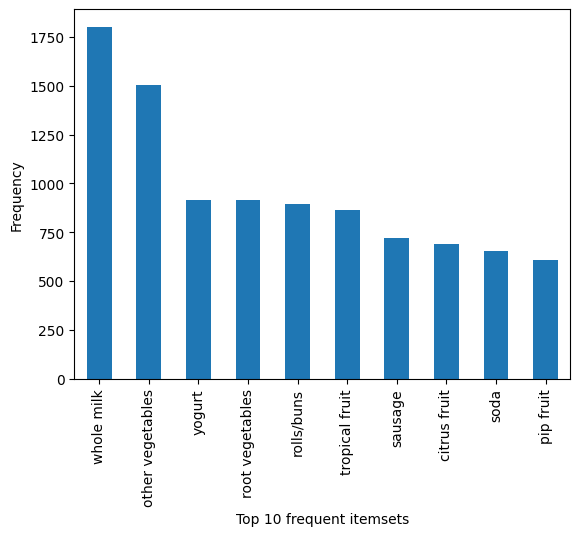

In [39]:
items.value_counts().head(10).plot(kind="bar")
plt.xlabel("Top 10 frequent itemsets")
plt.ylabel("Frequency")

**Creating a dummy dataset**

In [40]:
np.random.seed(42)


In [41]:
new_df = pd.DataFrame({
    'Receipt': np.random.randint(1, 1001, size=3537),  # Random integers from 1 to 1000
    'food': np.random.randint(1, 6, size=3537),        # Random integers from 1 to 5
    'quantity': np.random.randint(0, 50, size=3537)    # Random integers from 0 to 49
})


In [42]:
# Adjust 'Receipt' to match the statistics
new_df['Receipt'] = np.floor(new_df['Receipt'] * 0.498145321).astype(int)

# Adjust 'food' to match the statistics
new_df['food'] = np.random.normal(2.986146, 1.403204, size=3537).clip(1, 5).round().astype(int)

# Adjust 'quantity' to match the statistics
new_df['quantity'] = np.random.normal(24.222353, 14.722389, size=3537).clip(0, 49).round().astype(int)

# Verify the shape
print(new_df.shape)

(3537, 3)


In [43]:
#Display summary statistics
print(new_df.describe())

# Check for null values
print(new_df.isna().sum())

           Receipt         food     quantity
count  3537.000000  3537.000000  3537.000000
mean    249.888041     2.982188    24.323721
std     146.095380     1.254390    13.552002
min       0.000000     1.000000     0.000000
25%     122.000000     2.000000    14.000000
50%     251.000000     3.000000    24.000000
75%     379.000000     4.000000    34.000000
max     497.000000     5.000000    49.000000
Receipt     0
food        0
quantity    0
dtype: int64


In [44]:
new_df.to_csv('myfile.csv', index=False)

In [45]:
new_df=pd.read_csv("myfile.csv")

In [46]:
new_df.columns =[ "receipt", "food", "quantity"]

In [47]:
new_df.head()

,receipt,food,quantity
0,51,2,26
1,217,5,8
2,428,4,21
3,134,2,12
4,53,4,15


In [48]:
new_df.isna().sum()

receipt     0
food        0
quantity    0
dtype: int64

In [49]:
new_df.shape

(3537, 3)

In [50]:
new_df.describe()

,receipt,food,quantity
count,3537.000000,3537.000000,3537.000000
mean,249.888041,2.982188,24.323721
std,146.095380,1.254390,13.552002
min,0.000000,1.000000,0.000000
25%,122.000000,2.000000,14.000000
50%,251.000000,3.000000,24.000000
75%,379.000000,4.000000,34.000000
max,497.000000,5.000000,49.000000


In [51]:
new_df["food"] = new_df["food"].map({1:"milk", 2:"sugar", 3:"chocolate", 4:"apples", 5:"curd"}) 

In [52]:
new_df.head(5)

,receipt,food,quantity
0,51,sugar,26
1,217,curd,8
2,428,apples,21
3,134,sugar,12
4,53,apples,15


In [53]:
li=[]

In [59]:
for i in new_df["receipt"].unique():
    li.append([])

In [62]:
li = new_df.groupby("receipt")["food"].apply(list).tolist()

In [63]:
itemsets,rules = apriori(li, min_support=0.02, min_confidence=0.05)

In [64]:
itemsets

{1: {('apples',): 392,
  ('chocolate',): 423,
  ('curd',): 296,
  ('milk',): 327,
  ('sugar',): 392},
 2: {('apples', 'chocolate'): 337,
  ('apples', 'curd'): 230,
  ('apples', 'milk'): 258,
  ('apples', 'sugar'): 311,
  ('chocolate', 'curd'): 251,
  ('chocolate', 'milk'): 281,
  ('chocolate', 'sugar'): 337,
  ('curd', 'milk'): 194,
  ('curd', 'sugar'): 242,
  ('milk', 'sugar'): 254},
 3: {('apples', 'chocolate', 'curd'): 196,
  ('apples', 'chocolate', 'milk'): 225,
  ('apples', 'chocolate', 'sugar'): 269,
  ('apples', 'curd', 'milk'): 151,
  ('apples', 'curd', 'sugar'): 189,
  ('apples', 'milk', 'sugar'): 200,
  ('chocolate', 'curd', 'milk'): 163,
  ('chocolate', 'curd', 'sugar'): 207,
  ('chocolate', 'milk', 'sugar'): 219,
  ('curd', 'milk', 'sugar'): 159},
 4: {('apples', 'chocolate', 'curd', 'milk'): 128,
  ('apples', 'chocolate', 'curd', 'sugar'): 162,
  ('apples', 'chocolate', 'milk', 'sugar'): 175,
  ('apples', 'curd', 'milk', 'sugar'): 122,
  ('chocolate', 'curd', 'milk', 'suga

In [65]:
rules

[{chocolate} -> {apples},
 {apples} -> {chocolate},
 {curd} -> {apples},
 {apples} -> {curd},
 {milk} -> {apples},
 {apples} -> {milk},
 {sugar} -> {apples},
 {apples} -> {sugar},
 {curd} -> {chocolate},
 {chocolate} -> {curd},
 {milk} -> {chocolate},
 {chocolate} -> {milk},
 {sugar} -> {chocolate},
 {chocolate} -> {sugar},
 {milk} -> {curd},
 {curd} -> {milk},
 {sugar} -> {curd},
 {curd} -> {sugar},
 {sugar} -> {milk},
 {milk} -> {sugar},
 {chocolate, curd} -> {apples},
 {apples, curd} -> {chocolate},
 {apples, chocolate} -> {curd},
 {curd} -> {apples, chocolate},
 {chocolate} -> {apples, curd},
 {apples} -> {chocolate, curd},
 {chocolate, milk} -> {apples},
 {apples, milk} -> {chocolate},
 {apples, chocolate} -> {milk},
 {milk} -> {apples, chocolate},
 {chocolate} -> {apples, milk},
 {apples} -> {chocolate, milk},
 {chocolate, sugar} -> {apples},
 {apples, sugar} -> {chocolate},
 {apples, chocolate} -> {sugar},
 {sugar} -> {apples, chocolate},
 {chocolate} -> {apples, sugar},
 {apple

In [66]:
itemsets,rules = apriori(df1, min_support=0.1, min_confidence=0.2)

In [67]:
itemsets

{1: {('citrus fruit',): 691,
  ('pip fruit',): 609,
  ('yogurt',): 913,
  ('other vegetables',): 1497,
  ('whole milk',): 1792,
  ('rolls/buns',): 886,
  ('tropical fruit',): 866,
  ('root vegetables',): 915,
  ('sausage',): 723,
  ('soda',): 644},
 2: {('other vegetables', 'whole milk'): 577}}

In [68]:
rules

[{whole milk} -> {other vegetables}, {other vegetables} -> {whole milk}]

**Plotting most frequent item**

In [69]:
unique_food= new_df["food"].unique()

In [70]:
unique_food

array(['sugar', 'curd', 'apples', 'chocolate', 'milk'], dtype=object)

In [74]:
count = {}
for i in range(new_df.shape[0]):
    if new_df["food"][i] not in count:
        count[new_df["food"][i]] = new_df["quantity"][i]
    else:
        count[new_df["food"][i]] = new_df["quantity"][i] + count[new_df["food"][i]]

In [75]:
count

{'sugar': np.int64(18601),
 'curd': np.int64(11371),
 'apples': np.int64(20339),
 'chocolate': np.int64(23458),
 'milk': np.int64(12264)}

In [78]:
count = pd.Series(count)
count

sugar        18601
curd         11371
apples       20339
chocolate    23458
milk         12264
dtype: int64

Text(0, 0.5, 'Frequency')

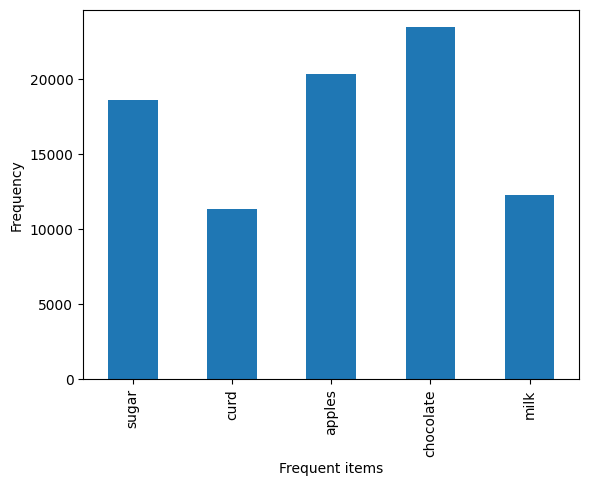

In [79]:
plt.figure()
count.plot(kind="bar")
plt.xlabel("Frequent items")
plt.ylabel("Frequency")

In [80]:
new_df.shape[0]

3537

In [81]:
new_df

,receipt,food,quantity
0,51,sugar,26
1,217,curd,8
2,428,apples,21
3,134,sugar,12
4,53,apples,15
...,...,...,...
3532,68,milk,31
3533,273,apples,32
3534,310,sugar,11
3535,494,sugar,35
